# 03 · Method research, P1: scoring

Each candidate answers a finding from [`reports/data_analysis.md`](../reports/data_analysis.md):

| | Candidate | Finding behind it |
|---|---|---|
| S1 | Scorecard: weight of evidence of the 8 analysed attributes (naive Bayes) | C: which attributes carry signal |
| S2 | Logistic regression, imputation + missing flags | C: thin, spread signal; NaN is informative |
| S3 | LightGBM, raw columns | C: non-monotonic relations, informative NaN |
| S4 | LightGBM + past-only behaviour features (**reference**, as in M2) | C: young cards; E: repeat fraud |
| S5 | S4 trained without weeks 0-3 | D: December 2017 is a different regime |
| S6 | S4 with sample weights proportional to amount | B: loss is concentrated in large transactions |
| S7 | S4 without the `entity_key` behaviour features | E: 78% of fraud is repeat fraud (risk of memorising people) |

Same split and LightGBM settings as M2, **no tuning**. Test = weeks 20-26. Results are written up in [`reports/method_research.md`](../reports/method_research.md).

In [1]:
import gc
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.baselines import fit_scorecard, score_scorecard, scorecard_bands
from fraud.config import load_config
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET, load_dataset, split_by_week
from fraud.evaluate import average_precision, bootstrap_ci, paired_bootstrap_diff, summarize, value_capture_at_rate
from fraud.features import add_past_features, add_row_features, feature_columns
from fraud.train import fit_lgbm, fit_logistic, log_run, predict

cfg = load_config("model")
N_BOOT, SEED = cfg["bootstrap"]["n_boot"], cfg["bootstrap"]["seed"]
FIG_DIR = Path("../reports/figures")

df = load_dataset("train")
raw_features = feature_columns(df)
df = add_past_features(add_row_features(df))
all_features = feature_columns(df)
entity_features = [f for f in all_features if f.startswith(ENTITY_COL + "_")]
train, valid, test = split_by_week(df, cfg["split"]["valid_start_week"], cfg["split"]["test_start_week"])

y_test = test[TARGET].to_numpy()
amount_test = test["TransactionAmt"].to_numpy(dtype=float)
groups_test = test[ENTITY_COL]
seen = test[ENTITY_COL].isin(train[ENTITY_COL].unique()).to_numpy()
print(f"train {len(train):,} / valid {len(valid):,} / test {len(test):,}; test rows from card holders seen in train: {seen.mean():.1%}")
print(f"features: raw {len(raw_features)}, all {len(all_features)}, of which entity-key behaviour features {len(entity_features)}")

train 386,298 / valid 83,079 / test 121,163; test rows from card holders seen in train: 33.9%
features: raw 431, all 447, of which entity-key behaviour features 6


## S1. Scorecard from the analysis

In [2]:
bands = scorecard_bands(df)
scorecard = fit_scorecard(bands.loc[train.index], train[TARGET])
scores = {"S1 scorecard": score_scorecard(scorecard, bands.loc[test.index])}
info = {"S1 scorecard": {"n_features": bands.shape[1]}}

woe = pd.concat({col: w for col, w in scorecard.woe.items()}, names=["attribute", "band"]).rename("weight_of_evidence")
print("Strongest bands (log-likelihood ratio, nats):")
woe.sort_values(key=abs, ascending=False).head(12).round(3)

Strongest bands (log-likelihood ratio, nats):


attribute        band           
V258             >=3                3.727
card6            debit or credit   -3.329
                 charge card       -2.805
card_age_D1      NaN               -2.235
V258             2                  1.659
C1               11-100             1.431
amount_decimals  2                 -1.316
                 3                  1.239
ProductCD        C                  1.230
DeviceType       mobile             1.082
hour             5-11               0.718
card_age_D1      >30               -0.670
Name: weight_of_evidence, dtype: float64

## S2. Logistic regression

In [3]:
t0 = time.time()
model = fit_logistic(train, all_features, C=cfg["logistic"]["C"], max_rows=cfg["logistic"]["max_rows"], seed=SEED)
scores["S2 logistic"] = predict(model, test, all_features)
info["S2 logistic"] = {"n_features": len(all_features), "seconds": round(time.time() - t0)}
del model
gc.collect();

## S3-S7. LightGBM variants

In [4]:
variants = {
    "S3 LightGBM raw": dict(features=raw_features),
    "S4 LightGBM + past features": dict(features=all_features),
    "S5 S4 without weeks 0-3": dict(features=all_features, train=train[train["week"] >= 4]),
    "S6 S4 weighted by amount": dict(features=all_features, weighted=True),
    "S7 S4 without entity features": dict(features=[f for f in all_features if f not in entity_features]),
}
for name, spec in variants.items():
    tr = spec.get("train", train)
    weight = (tr["TransactionAmt"] / tr["TransactionAmt"].mean()).to_numpy(dtype=float) if spec.get("weighted") else None
    t0 = time.time()
    model = fit_lgbm(tr, valid, spec["features"], cfg["lgbm"], seed=SEED, sample_weight=weight)
    scores[name] = predict(model, test, spec["features"])
    info[name] = {"n_features": len(spec["features"]), "train_rows": len(tr), "best_iteration": model.best_iteration_, "seconds": round(time.time() - t0)}
    print(f"{name}: {info[name]}")
    del model
    gc.collect()

S3 LightGBM raw: {'n_features': 431, 'train_rows': 386298, 'best_iteration': 247, 'seconds': 50}


S4 LightGBM + past features: {'n_features': 447, 'train_rows': 386298, 'best_iteration': 2488, 'seconds': 350}


S5 S4 without weeks 0-3: {'n_features': 447, 'train_rows': 262964, 'best_iteration': 1660, 'seconds': 155}


S6 S4 weighted by amount: {'n_features': 447, 'train_rows': 386298, 'best_iteration': 2115, 'seconds': 305}


S7 S4 without entity features: {'n_features': 441, 'train_rows': 386298, 'best_iteration': 238, 'seconds': 46}


## Results on the test weeks

- **PR-AUC** with a 95% CI over card holders.
- **$ PR-AUC**: the same curve with every transaction weighted by its amount (precision and recall in dollars).
- **$ caught at 1% / 3%**: share of fraud dollars among the 1% / 3% highest-scored transactions, i.e. what a decline budget of that size would stop.
- **Seen / unseen**: PR-AUC on card holders that do / do not appear in the training weeks.

In [5]:
rows = []
for name, s in scores.items():
    ci = bootstrap_ci(y_test, s, groups=groups_test, n_boot=N_BOOT, seed=SEED)
    usd = bootstrap_ci(y_test, s, groups=groups_test, n_boot=N_BOOT, seed=SEED, weight=amount_test)
    row = {
        "pr_auc": ci.estimate, "ci_low": ci.low, "ci_high": ci.high,
        "usd_pr_auc": usd.estimate, "usd_ci_low": usd.low, "usd_ci_high": usd.high,
        "usd_caught_1pct": value_capture_at_rate(y_test, s, amount_test, 0.01),
        "usd_caught_3pct": value_capture_at_rate(y_test, s, amount_test, 0.03),
        "pr_auc_seen": average_precision(y_test[seen], s[seen]),
        "pr_auc_unseen": average_precision(y_test[~seen], s[~seen]),
        "log_loss": summarize(y_test, s)["log_loss"],
    }
    rows.append({"model": name, **row})
    log_run(name, {"model": name, **info[name]}, row, [], experiment="method-research-scoring")
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,pr_auc,ci_low,ci_high,usd_pr_auc,usd_ci_low,usd_ci_high,usd_caught_1pct,usd_caught_3pct,pr_auc_seen,pr_auc_unseen,log_loss
model,,,,,,,,,,,
S1 scorecard,0.2879,0.2547,0.3268,0.1782,0.1559,0.2025,0.0679,0.1309,0.1433,0.3157,0.1767
S2 logistic,0.4042,0.3654,0.4475,0.3214,0.2873,0.3604,0.1258,0.3043,0.1996,0.4402,0.1109
S3 LightGBM raw,0.5045,0.4735,0.5323,0.4298,0.3933,0.4686,0.1364,0.3843,0.5216,0.5127,0.0993
S4 LightGBM + past features,0.5337,0.5037,0.5614,0.4480,0.4095,0.4883,0.1629,0.4066,0.6370,0.5263,0.1710
S5 S4 without weeks 0-3,0.5247,0.4948,0.5518,0.4421,0.4002,0.4847,0.1597,0.4279,0.6233,0.5209,0.1616
S6 S4 weighted by amount,0.5177,0.4883,0.5445,0.4435,0.4045,0.4819,0.1622,0.3486,0.5905,0.5159,0.1603
S7 S4 without entity features,0.5156,0.4860,0.5447,0.4370,0.3975,0.4774,0.1550,0.4007,0.5458,0.5213,0.0976


In [6]:
reference = "S4 LightGBM + past features"
diffs = pd.DataFrame([
    {
        "model": name,
        **{f"pr_auc_{k}": v for k, v in paired_bootstrap_diff(y_test, scores[reference], s, groups=groups_test, n_boot=N_BOOT, seed=SEED)._asdict().items()},
        **{f"usd_pr_auc_{k}": v for k, v in paired_bootstrap_diff(y_test, scores[reference], s, groups=groups_test, n_boot=N_BOOT, seed=SEED, weight=amount_test)._asdict().items()},
    }
    for name, s in scores.items() if name != reference
]).set_index("model")
print(f"Difference vs {reference} (positive = better than the reference), 95% CI over card holders")
diffs.round(4)

Difference vs S4 LightGBM + past features (positive = better than the reference), 95% CI over card holders


,pr_auc_estimate,pr_auc_low,pr_auc_high,usd_pr_auc_estimate,usd_pr_auc_low,usd_pr_auc_high
model,,,,,,
S1 scorecard,-0.2458,-0.2771,-0.2104,-0.2699,-0.3115,-0.2268
S2 logistic,-0.1296,-0.1684,-0.0908,-0.1266,-0.1639,-0.0866
S3 LightGBM raw,-0.0293,-0.0443,-0.0145,-0.0182,-0.0392,0.0019
S5 S4 without weeks 0-3,-0.0091,-0.0165,-0.0018,-0.0059,-0.0194,0.0079
S6 S4 weighted by amount,-0.0160,-0.0241,-0.0073,-0.0045,-0.0156,0.0081
S7 S4 without entity features,-0.0181,-0.0290,-0.0079,-0.0110,-0.0259,0.0038


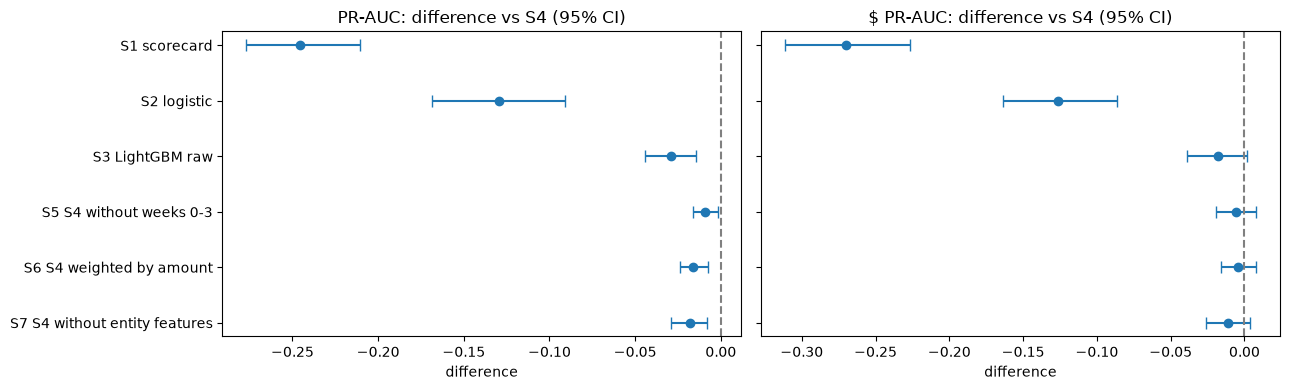

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = diffs.index[::-1]
for ax, prefix, title in [(axes[0], "pr_auc", "PR-AUC"), (axes[1], "usd_pr_auc", "$ PR-AUC")]:
    est = diffs.loc[order, f"{prefix}_estimate"]
    err = np.vstack([est - diffs.loc[order, f"{prefix}_low"], diffs.loc[order, f"{prefix}_high"] - est])
    ax.errorbar(est, range(len(order)), xerr=err, fmt="o", capsize=4)
    ax.axvline(0, color="gray", ls="--")
    ax.set(title=f"{title}: difference vs S4 (95% CI)", xlabel="difference")
axes[0].set_yticks(range(len(order)), order)
fig.tight_layout()
fig.savefig(FIG_DIR / "mr_scoring_diffs.png", dpi=120, bbox_inches="tight")

fraud rate: seen 1.66%, new 4.37%


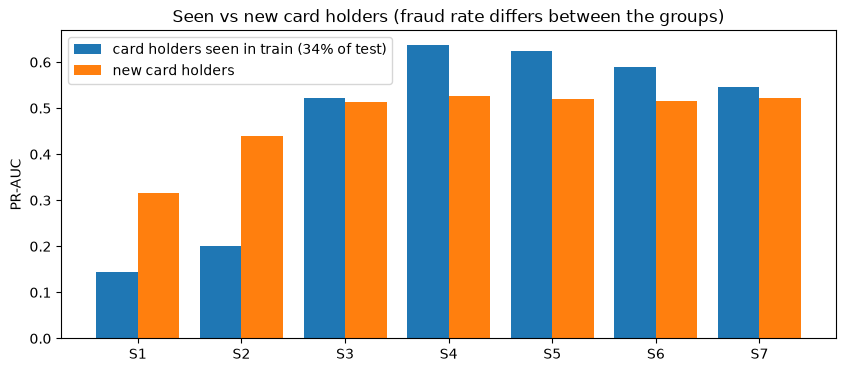

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(results))
ax.bar(x - .2, results["pr_auc_seen"], .4, label=f"card holders seen in train ({seen.mean():.0%} of test)")
ax.bar(x + .2, results["pr_auc_unseen"], .4, label="new card holders")
ax.set_xticks(x, [n.split(" ", 1)[0] for n in results.index])
ax.set(ylabel="PR-AUC", title="Seen vs new card holders (fraud rate differs between the groups)")
ax.legend()
fig.savefig(FIG_DIR / "mr_scoring_seen_unseen.png", dpi=120, bbox_inches="tight")
print(f"fraud rate: seen {y_test[seen].mean():.2%}, new {y_test[~seen].mean():.2%}")

In [9]:
out = test[["TransactionID", "week", "day", ENTITY_COL, "TransactionAmt", "ProductCD", TARGET]].assign(**{
    name.split(" ", 1)[0]: s for name, s in scores.items()
})
out.to_parquet(PROCESSED_DIR / "scores_p1.parquet", index=False)
print(f"saved test scores of {len(scores)} candidates")

saved test scores of 7 candidates
